# Plano city · current prototype and evaluation

This is the current scope: **official Plano municipal limits**, with 1 km walking-network and destination context. The earlier four-ZIP analysis remains an archive.

Live app: https://empathmaps.netlify.app/app.html . Select categories, choose a ranked housing-positive block, then inspect actual minimum-friction routes. Routes start at snapped junctions; entrances and connectors are not validated.


scope             Official Plano municipal boundary
weighted_edges                               193128
blocks                                         4402
pois                                            883
Name: Current scope, dtype: object

Complete essential scores: 4331
Census housing-positive blocks: 2852


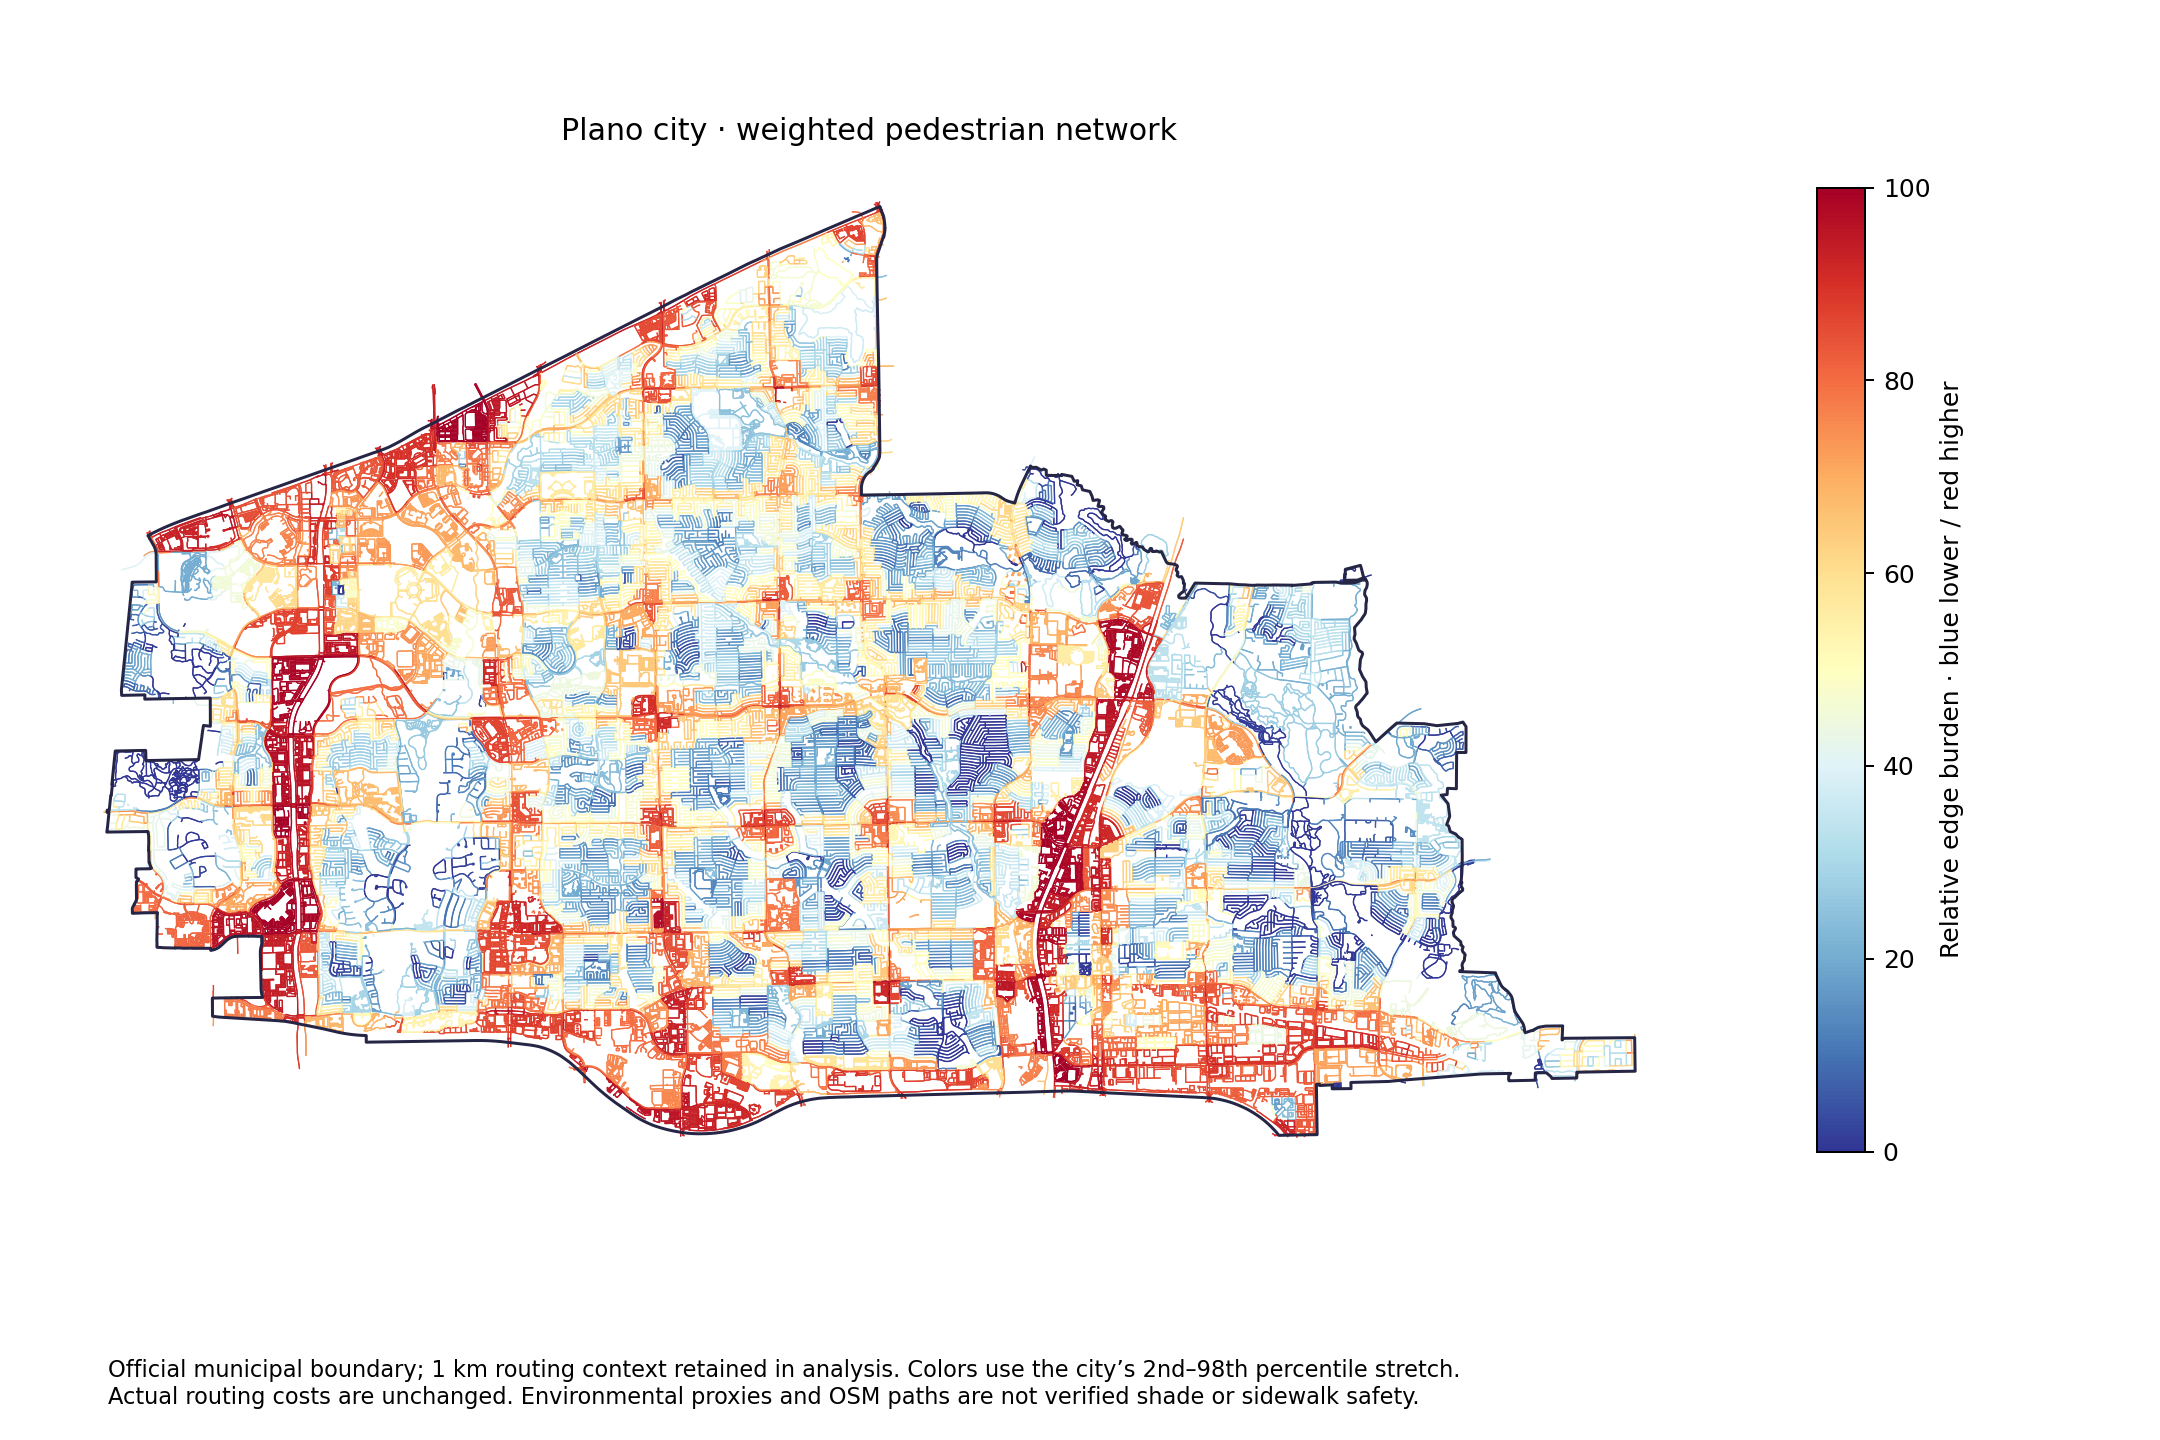

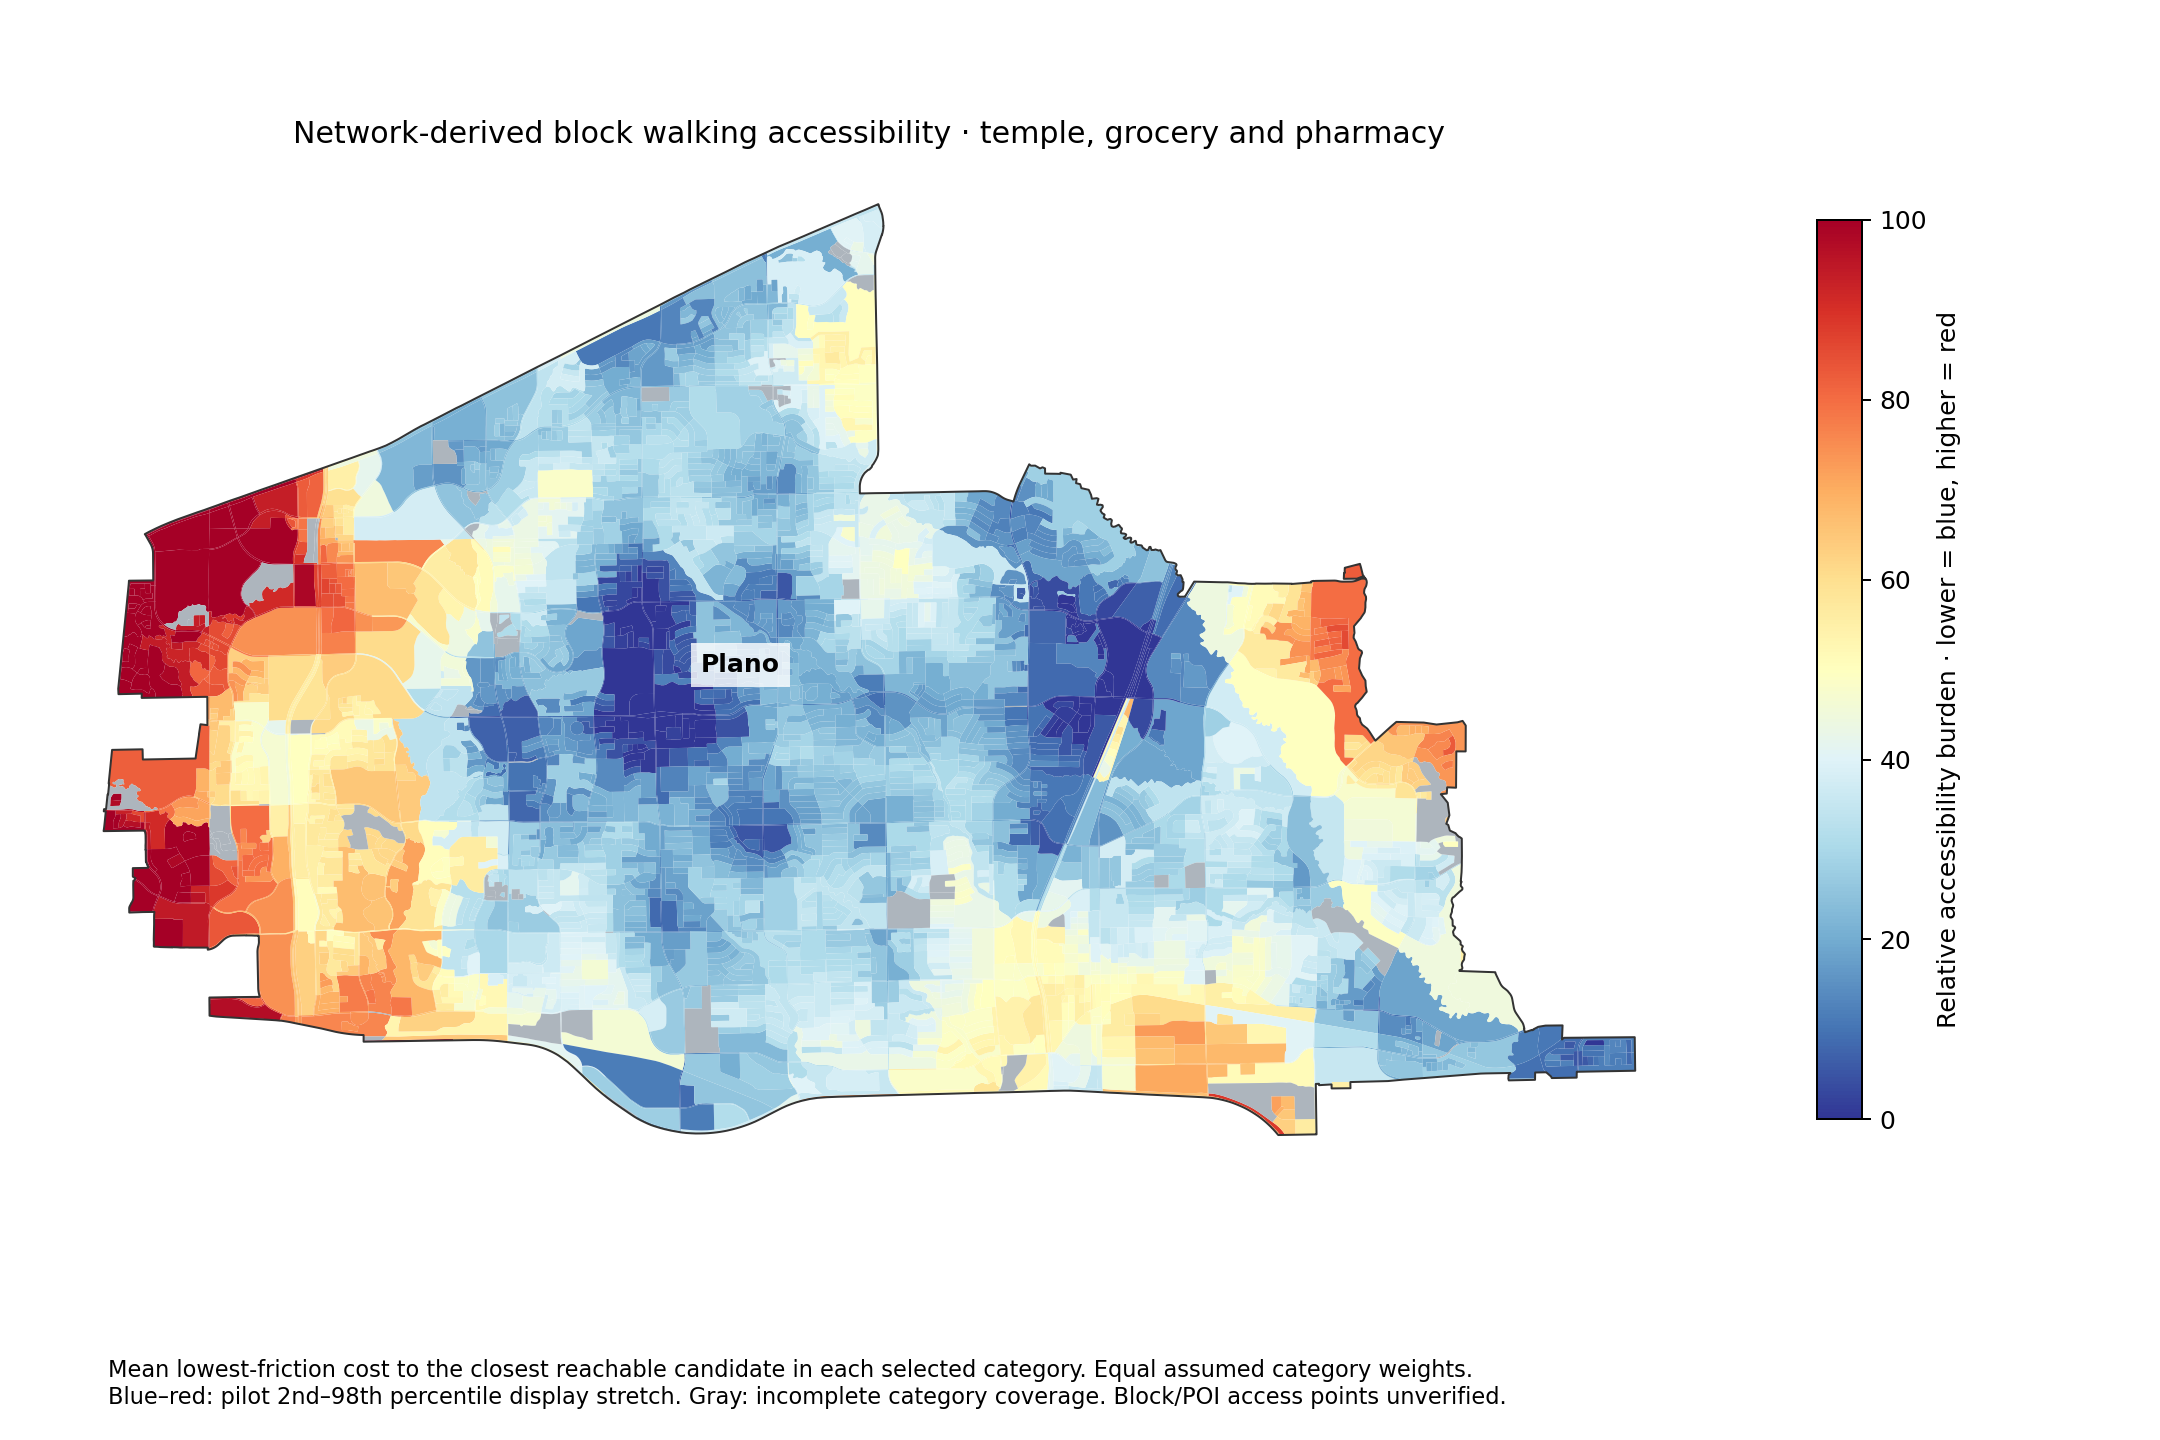

In [1]:
from pathlib import Path
import json,pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
OUT=ROOT/'output/plano_city/accessibility'
method=json.loads((OUT/'accessibility_method.json').read_text())
display(pd.Series({k:method[k] for k in ['scope','weighted_edges','blocks','pois']},name='Current scope'))
blocks=pd.read_csv(OUT/'block_accessibility.csv',dtype={'GEOID20':str})
print('Complete essential scores:',blocks.access_essential_mean_equiv_min.notna().sum())
print('Census housing-positive blocks:',(blocks.HU100>0).sum())
display(Image(filename=str(OUT/'plano_weighted_network.png')))
display(Image(filename=str(OUT/'block_accessibility_essential.png')))


## Evaluate the result

1. Check mathematical consistency: edge equation, nonnegative costs, nearest-category minima, aggregation and browser route/score agreement.
2. Compare time-only and friction on identical network support.
3. Change plausible factor weights and selected categories; inspect ranking sensitivity.
4. Review actual routes against public imagery/municipal trails and access information. Record failures; do not certify access from network connectivity alone.
5. Distinguish prediction coverage from accuracy, and assumed friction from learned preferences.

The public validation page reports measured results and clearly separates pending manual checks: https://empathmaps.netlify.app/validation.html .


In [2]:
for name in ['evaluation_baseline.json','evaluation_sensitivity.json','route_benchmark_city_method.json']:
    print(name)
    display(json.loads((OUT/name).read_text()))
display(pd.read_csv(OUT/'manual_route_review_template.csv').head())


evaluation_baseline.json


{'all_categories': {'matched_blocks': 4331,
  'spearman_rank_correlation': 0.9949316169050834,
  'top20_overlap': 20,
  'median_time_only_minutes': 41.02944498989399,
  'median_friction_equivalent_minutes': 69.83848211890044,
  'same_graph_support': True},
 'essential': {'matched_blocks': 4331,
  'spearman_rank_correlation': 0.9942515749210371,
  'top20_overlap': 20,
  'median_time_only_minutes': 30.729679871988,
  'median_friction_equivalent_minutes': 51.88027629691465,
  'same_graph_support': True},
 'origin_snap_gaps_over_100m': 546,
 'not_accuracy': 'These measure implementation and ranking differences, not agreement with local human preferences. Baseline uses identical supported network but optimizes time and may choose a different destination.'}

evaluation_sensitivity.json


{'profile': ['hindu_temple', 'supermarket', 'pharmacy'],
 'eligible_housing_blocks': 2346,
 'scenarios': {'equal': {'factor_weights_canopy_traffic_heat': [0.3333333333333333,
    0.3333333333333333,
    0.3333333333333333],
   'eligible_complete_blocks': 2346,
   'spearman_vs_equal': 0.9999999999999998,
   'top20_overlap_with_equal': 20,
   'median_cost_equiv_min': 50.70645152036239},
  'canopy_priority': {'factor_weights_canopy_traffic_heat': [0.6, 0.2, 0.2],
   'eligible_complete_blocks': 2346,
   'spearman_vs_equal': 0.9989545075915519,
   'top20_overlap_with_equal': 20,
   'median_cost_equiv_min': 53.06291603345562},
  'traffic_priority': {'factor_weights_canopy_traffic_heat': [0.2, 0.6, 0.2],
   'eligible_complete_blocks': 2346,
   'spearman_vs_equal': 0.9965223479575152,
   'top20_overlap_with_equal': 20,
   'median_cost_equiv_min': 48.80960895588611},
  'heat_priority': {'factor_weights_canopy_traffic_heat': [0.2, 0.2, 0.6],
   'eligible_complete_blocks': 2346,
   'spearman_vs_e

route_benchmark_city_method.json


{'sample': 'Six distinct housing-positive, <=100m-snap blocks: lowest/highest essential cost and north/south/east/west extremes; three essential categories each. Same destination for both route objectives.',
 'pairs': 18,
 'different_routes': 12,
 'weighted_objective_checks_passed': True,
 'mean_extra_actual_walk_minutes': 0.2544617076010343,
 'pairs_with_less_busy_road_length': 2,
 'interpretation': 'Model optimization and exposure-proxy comparison, not a human preference accuracy test or a guarantee of access. The sample is small and not representative of all households.'}

,GEOID20,sample_reason,snap_gap_m,review_status,entrance_and_connector_check,crossings_and_barriers_check,public_access_and_destination_check,trail_vs_road_observation,notes,app_url
0,480850316822002,low_cost,74.808618,NOT REVIEWED,NaN,NaN,NaN,NaN,NaN,https://empathmaps.netlify.app/app.html?catego...
1,481210216261019,high_cost,58.214492,NOT REVIEWED,NaN,NaN,NaN,NaN,NaN,https://empathmaps.netlify.app/app.html?catego...
2,480850316662007,large_snap_gap,323.524781,NOT REVIEWED,NaN,NaN,NaN,NaN,NaN,https://empathmaps.netlify.app/app.html?catego...
3,480850316652024,unreachable_reference,11.345924,NOT REVIEWED,NaN,NaN,NaN,NaN,NaN,https://empathmaps.netlify.app/app.html?catego...
4,480850316652009,north,10.055785,NOT REVIEWED,NaN,NaN,NaN,NaN,NaN,https://empathmaps.netlify.app/app.html?catego...


## Source and rebuild stages

- `prepare_plano_city_context.py`: Census block context and city-referenced traffic.
- `bootstrap_plano_city_geoai.py`: reuse compatible classes, infer missing city-context imagery.
- `landsat_summer_heat.py`: accepts EMPATH_HEAT_OUTPUT, EMPATH_HEAT_SCOPE and EMPATH_HEAT_BLOCKS to keep city results separate.
- `summarize_plano_city_geoai.py`: city/context block summaries.
- `enrich_plano_housing.py`: complete public HU100/POP100 metadata.
- `extract_city_pbf_native.py` → `build_plano_city_graph_from_pbf.py` → `prepare_plano_city_network.py`: verified PBF and real graph identities.
- `block_proxy_friction.py`: accepts explicit edge/block/output paths for city weights.
- `EMPATH_CITY_MODE=1` with `score_block_accessibility.py`, `export_routing_network.py`, `map_block_accessibility.py`, `build_accessibility_app.py`.
- `evaluate_plano_city.py`, `evaluate_city_routes.py`, `build_plano_evaluation_page.py`: measurable evaluation and pending-review template.

See `docs/PLANO_CITY_STATUS.md` for data vintages, limitations and current counts. Large data caches and authenticated generated HTML remain excluded from Git. No countywide scores are implied.
